In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import scipy as sp
import sys
sys.path.insert(1, '../')
import util

from scipy.stats import qmc
from numpy.random import Generator, PCG64
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
# from mpl_toolkits.basemap import Basemap
import matplotlib as mpl
import tqdm
from pathlib import Path
from scipy.signal import argrelextrema
# import seaborn as sns
from util.plot import lighten_color

def stat_dist_theory_res(D,*data):
    A,q_c,q_r = data
    x_pos = np.dot(np.transpose(np.where(A>=0,A,0)),D)
    x_neg = np.dot(np.transpose(np.where(A<0,-A,0)),D)
    # out = np.zeros(len(D))
    # for i in range(len(D)):
    #     out[i] = D[i] - (1+x_pos[i])*q_c[i]/((1+x_pos)*q_c[i] + (1+x_neg)*q_r[i])
    out = D - (1+x_pos)*q_c/((1+x_pos)*q_c + (1+x_neg)*q_r)
    return out

# Pre-processing

In [4]:
%run DataProcessingTE.py
# Outputs the following:
    # df_AM22 - processed individual TE data from Armstrong McKay et al 2022
    # df_W24 - TE-TE interactions from Wunderling et al 2024
    # df_SSPs - global mean surface temp. anomalies vs pre-industrial (1850-1900). Historical and several SSPs
        # See scenarios for the list of scenarios 

# Loading pre-saved interaction matrices
A = [np.loadtxt("../../Data/Simulations/TE/Interaction matrices/A_%s.csv"%r) for r in range(500)]

# (re)-calculating sigmoid betas with value at T_min of 0.001 (i.e. 0.1%)
betas = []
value_at_min=0.001
for x in df_AM22[['Threshold (°C) - Min.','Threshold (°C) - Est.','Threshold (°C) - Max.']].values:
    betas.append(float(sigmoid_beta(x[0],x[1],x[2],value_at_min=value_at_min)))
df_AM22['Sigmoid Beta'] = betas
Tmin = df_AM22.loc['ENSO']['Threshold (°C) - Min.']
Tmax = df_AM22.loc['ENSO']['Threshold (°C) - Max.']
df_AM22.loc['ENSO','Sigmoid Beta'] = np.log(1/value_at_min - 1)/(np.mean([Tmin,Tmax])-Tmin)
betas = df_AM22['Sigmoid Beta'].to_numpy() # important to turn into numpy array for computational speed!!

q_c = 1/(df_AM22['CollapseTime'].to_numpy()+1) # collapse leverage
T_lim = np.array(df_AM22['T_lim'].to_list()) # tipping thresholds
p_r = 1/(10*df_AM22['CollapseTime'].to_numpy()+1) # recovery probabilities: $\tau_{r,i} = 10\tau_{c,i}$

Exception: File `'DataProcessingTE.py'` not found.

In [3]:
df_AM22['Sigmoid Beta']

AMAZ     4.604503
AMOC     2.656444
ASI      3.837086
ENSO     4.604503
GIS      9.866793
PERM     6.906755
REEF    13.813510
WAIS    13.813510
WAM      8.633443
Name: Sigmoid Beta, dtype: float64

# Equilibrium solutions under fixed GMST

## Reading data

In [13]:
folder = "../../Data/Interaction matrices/"
no_samples = 500
A = [np.loadtxt(folder+'A_'+str(r)+'.csv') for r in range(no_samples)]

folder_data = '../../Data/'
df_TEs = pd.read_excel(folder_data+'TEsummary.xlsx',header=[0],index_col=0)
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy() # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy() # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
p_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

TEs = df_TEs.index.to_numpy()

In [14]:
TEs

array(['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS',
       'WAM'], dtype=object)

## Numerically solving the 9 coupled equations

In [7]:
T = np.arange(0,10,step=0.001)
D_theory = np.array([[sp.optimize.fsolve(stat_dist_theory_res, 
                                        np.ones(9), 
                                        args=(A[r],util.dynamics.temp_response(t, T_lim,betas)*q_c,p_r)) 
                     for t in T] for r in tqdm.tqdm(range(500))])

D_theory_noint = np.array([sp.optimize.fsolve(stat_dist_theory_res, 
                                              np.ones(9), 
                                              args=(np.zeros(9),util.dynamics.temp_response(t, T_lim,betas)*q_c,p_r)) 
                           for t in tqdm.tqdm(T)])

100%|█████████████████████████████████████████████████████████████████████████████████| 10000/10000 [00:02<00:00, 3711.02it/s]


In [15]:
# Saving the data
folder= "../Data/Simulations/TE/Sigmoid/rx10c/Stat dist over GMST/"
Path(folder[:-1]).mkdir(parents=True, exist_ok=True)
for i,te in enumerate(TEs):
    np.savetxt(folder+"D_"+te+".csv", D_theory[:,:,i])
    np.savetxt(folder+"D_no_interaction_"+te+".csv", D_theory_noint[:,i])

## Visualisation

### Loading data

In [3]:
folder= "../Data/Simulations/TE/Sigmoid/rx10c/Stat dist over GMST/"
D_theory = np.array([np.loadtxt(folder+"D_"+te+".csv") 
                     for i,te in enumerate(TEs)]).transpose((1,2,0))
D_theory_noint = np.array([np.loadtxt(folder+"D_no_interaction_"+te+".csv") 
                           for i,te in enumerate(TEs)]).transpose()
T = np.arange(0,10,step=0.001)

In [4]:
TEs

['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS', 'WAM']

In [6]:
D_theory[:,np.where(T==1.6)[0][0],-3].mean()

0.8800787999040302

### 1.6C

Text(0.5, 0, 'Tipping element')

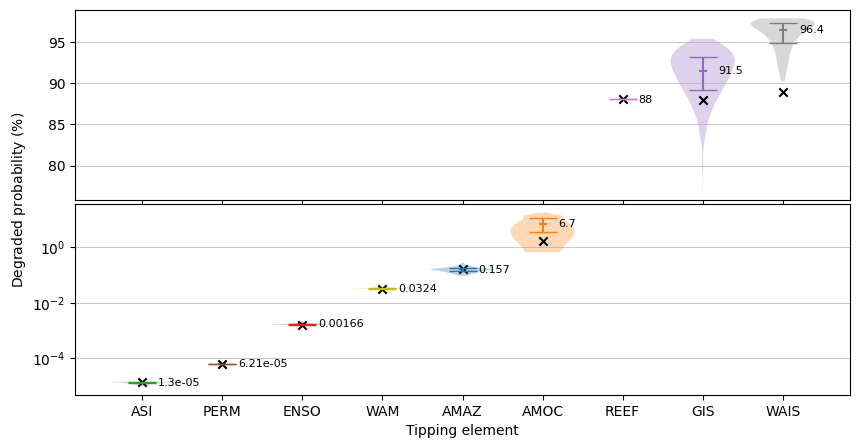

In [16]:
fig,axs = plt.subplots(2,1,sharex=True,figsize=(10,5))
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']

fig.subplots_adjust(hspace=0.02)

D_16 = D_theory[:,1600,:]
D_16_noint = D_theory_noint[1600,:]
y= np.median(D_16,axis=0)*100
yerr = np.abs(np.quantile(D_16*100,[0.25,0.75],axis=0)-y)
full = sorted(zip(list(y),TEs,range(9)))

# ax.set_yscale('log')
for i in range(9):
    i_ax=full[i][2]
    ax_num = int(i<=5)
    vp=axs[ax_num].violinplot(D_16[:,i_ax]*100,positions=[i+1],showmeans=False, showmedians=False,
        showextrema=False, widths=0.8)
    for b in vp['bodies']:
        b.set_facecolor(colors[i_ax])
    axs[ax_num].scatter([i+1],y[i_ax],color=util.plot.lighten_color(colors[i_ax],1),marker='_')
    axs[ax_num].errorbar([i+1],y[i_ax],yerr=yerr[:,i_ax].reshape(2,1),ls='',ecolor=util.plot.lighten_color(colors[i_ax],1),
                marker='',barsabove=True,capsize=10)
    # if i > 1:
    axs[ax_num].annotate('%.3g'%(y[i_ax]),[i+1.2,y[i_ax]],ha='left',va='center',fontsize=8)

axs[1].set_yscale('log')
ylim0 = axs[0].get_ylim()
ylim1 = axs[1].get_ylim()

axs[0].scatter(np.arange(1,10),[100*D_16_noint[i] for _,_,i in full],marker='x',color='k')
axs[1].scatter(np.arange(1,10),[100*D_16_noint[i] for _,_,i in full],marker='x',color='k')

axs[0].set_ylim(ylim0)
axs[1].set_ylim(ylim1)

axs[0].grid(visible=True,lw=0.5,axis='y')
axs[1].grid(visible=True,lw=0.5,axis='y')
# hide the spines between ax and ax2
# axs[0].spines.bottom.set_visible(False)
# axs[1].spines.top.set_visible(False)
axs[0].set_xticks([])  # don't put tick labels at the top
axs[1].xaxis.tick_bottom()

plt.xticks(np.arange(1,10), [te for _,te,_ in full]);
fig.text(0.06, 0.5, r"Degraded probability ($\%$)", va='center', rotation='vertical')
axs[1].set_xlabel("Tipping element")

# fig.savefig("../Figures/TE (sigmoid)/rx10c/GMSTs_1_6.pdf",format='pdf',bbox_inches='tight',dpi=300)

In [26]:
TEs

['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS', 'WAM']

In [27]:
D_theory[:,-1,-3].mean(axis=0)

0.9747840067779937

In [21]:
print('GIS max temp: ', T[np.argmin(np.abs(D_theory[:,:,4].mean(axis=0) - np.max(D_theory[:,:,4].mean(axis=0))))] )

GIS max temp:  1.7530000000000001


In [29]:
print(D_theory[:,np.where(T==5),4].mean(axis=0))

[[0.77860466]]


(-0.5, 0.5)

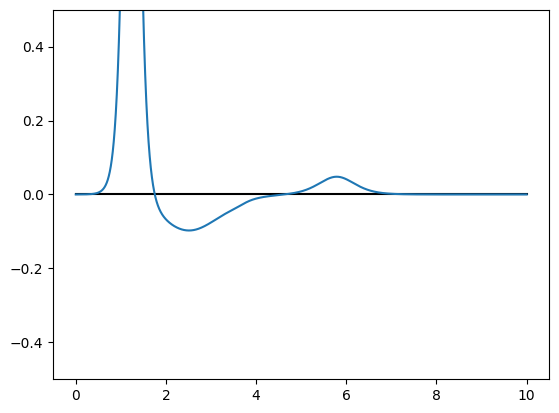

In [25]:
plt.plot([0,10],[0,0],'k')
plt.plot(T, np.gradient(D_theory[:,:,4].mean(axis=0),0.001))
plt.ylim([-0.5,0.5])

### Individual TEs

NameError: name 'df_AM22' is not defined

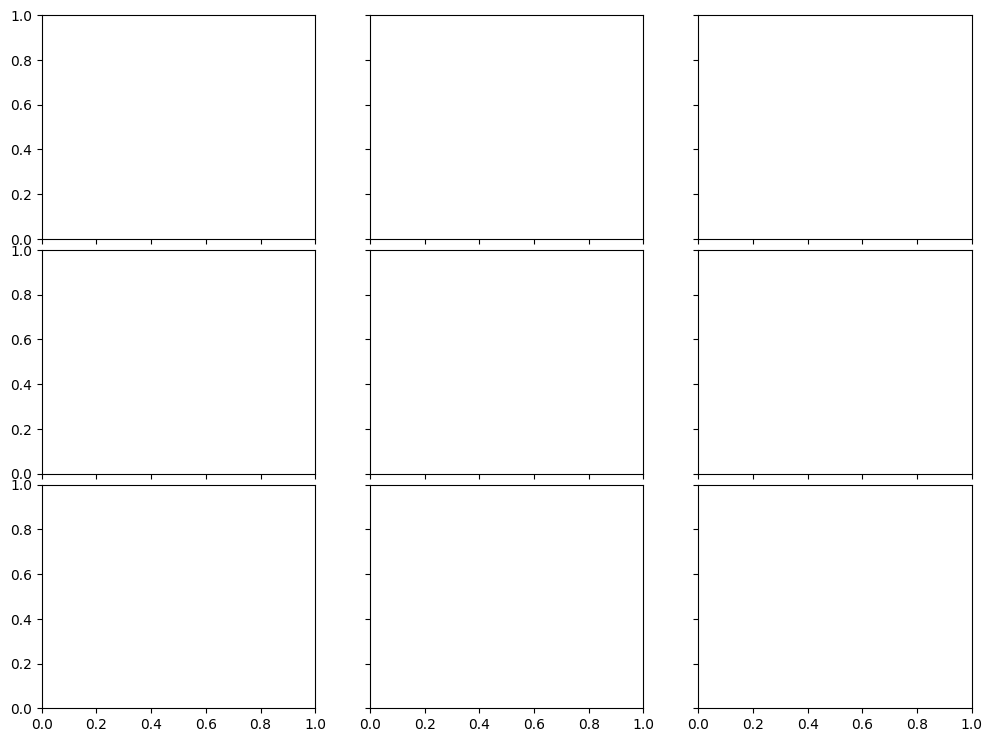

In [17]:
T = np.arange(0,10,step=0.001)
fig,axs = plt.subplots(figsize=(12,9),nrows=3,ncols=3,sharex=True,sharey=True)
# fig.subplots_adjust(hspace=0.05)
fig.subplots_adjust(hspace=0.05)

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
# linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--',(5,(10,3))]
# scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']

TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']

ann_ind = {0:1, 1:1, 2:1, 3:1, 7:1, 
           4:1, 5:1, 6:1, 8:1}
locs = [(0.05,0.95),(0.95,0.05)]
has = ['left','right']
vas = ['top','bottom']
TE_ind = {te:i for i,te in enumerate(TEs)}

T_min = df_AM22['Threshold (°C) - Min.'].to_numpy()
T_max = df_AM22['Threshold (°C) - Max.'].to_numpy()
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    # axs[i_ax//3,i_ax%3].plot([1.2,1.2],[0,100],c='k')
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='y')
    # axs[i_ax//3,i_ax%3].fill_between([T_min[i],T_max[i]],[0,0],[100,100],color=util.lighten_color('k',1),alpha=1)
    # axs[i_ax//3,i_ax%3].plot([0,10],[0]*2, c='k',lw=0.75)
    # axs[i_ax//3,i_ax%3].plot([0,10],[100]*2, c='k',lw=0.75)
    axs[i_ax//3,i_ax%3].annotate(letters[i_ax] + ' '+ TEs[i],
                                 locs[ann_ind[i_ax]],
                                 xycoords='axes fraction',
                                 ha=has[ann_ind[i_ax]],
                                 va=vas[ann_ind[i_ax]],
                                 fontsize=12,
                                 bbox=dict(fc='white',
                                           edgecolor='0.7',
                                           boxstyle='round'))
    axs[i_ax//3,i_ax%3].plot([T_lim[i]]*2,[0,100],c=util.lighten_color(colors[i],1.35),ls=':',lw=1)
    axs[i_ax//3,i_ax%3].plot([T_min[i]]*2,[0,100],c=util.lighten_color(colors[i],1.35),ls=':',lw=1)
    axs[i_ax//3,i_ax%3].plot([T_max[i]]*2,[0,100],c=util.lighten_color(colors[i],1.35),ls=':',lw=1)

    # for r in range(500):
    #     axs[i_ax//3,i_ax%3].plot(T,D_theory[r,:,i]*100,
    #                              c=colors[i], 
    #                              ls='-',lw=0.01)
    axs[i_ax//3,i_ax%3].fill_between(T, 
                                     np.quantile(D_theory[:,:,i]*100,0.05,axis=0),
                                     np.quantile(D_theory[:,:,i]*100,0.95,axis=0),
                                     color=util.lighten_color(colors[i],0.3),
                                     edgecolor=util.lighten_color(colors[i],0.3),
                                     alpha=1)
    axs[i_ax//3,i_ax%3].fill_between(T, 
                                     np.quantile(D_theory[:,:,i]*100,0.25,axis=0),
                                     np.quantile(D_theory[:,:,i]*100,0.75,axis=0),
                                     color=util.lighten_color(colors[i],0.65),
                                     edgecolor=util.lighten_color(colors[i],0.65),
                                     alpha=1)
    axs[i_ax//3,i_ax%3].plot(T,D_theory[:,:,i].mean(axis=0)*100,
                             c=util.lighten_color(colors[i],1.35), 
                             ls='-',lw=1)

    axs[i_ax//3,i_ax%3].plot(T,D_theory_noint[:,i]*100,
                             c=util.lighten_color(colors[i],1.35), 
                             ls='--',lw=1)


lines=[
       Line2D([0], [0], color='k', lw=2, label='Sans interactions',ls='--'),
       Line2D([0], [0], color='k', lw=2, label='Mean'),
       Patch(facecolor=util.lighten_color('k',0.3), 
             edgecolor=util.lighten_color('k',0.3), label='$(P_5,P_{95})$'),
       Patch(facecolor=util.lighten_color('k',0.65), 
             edgecolor=util.lighten_color('k',0.65), label='$(P_{25},P_{75})$'),
    Line2D([0], [0], color='k', lw=2, label='Threshold',ls=':')] 
# lines += [Line2D([0], [0], color='k', lw=2, 
#                  label=scen_labels[j], ls = linestyles[j]) for j in range(5)]


# fig.text(0.5, 0.04, 'Fixed GMST anomaly (℃)', ha='center')
# fig.text(0.04, 0.5, 'Stationary degraded prob. (%)', va='center', rotation='vertical')
for i in range(3):
    axs[-1,i].set_xlabel('Fixed GMST anomaly (℃)')
    axs[i,0].set_ylabel('Degraded prob. (%)')
    
axs[0,0].set_xlim([0,10])
# axs[0,0].set_ylim([0,100])

fig.legend(handles=lines,ncols=6,loc='upper center',prop={'size':12},borderaxespad=2)
# fig.savefig("../Figures/TE (sigmoid)/rx10c/GMSTs.pdf",format='pdf',bbox_inches='tight',dpi=300)

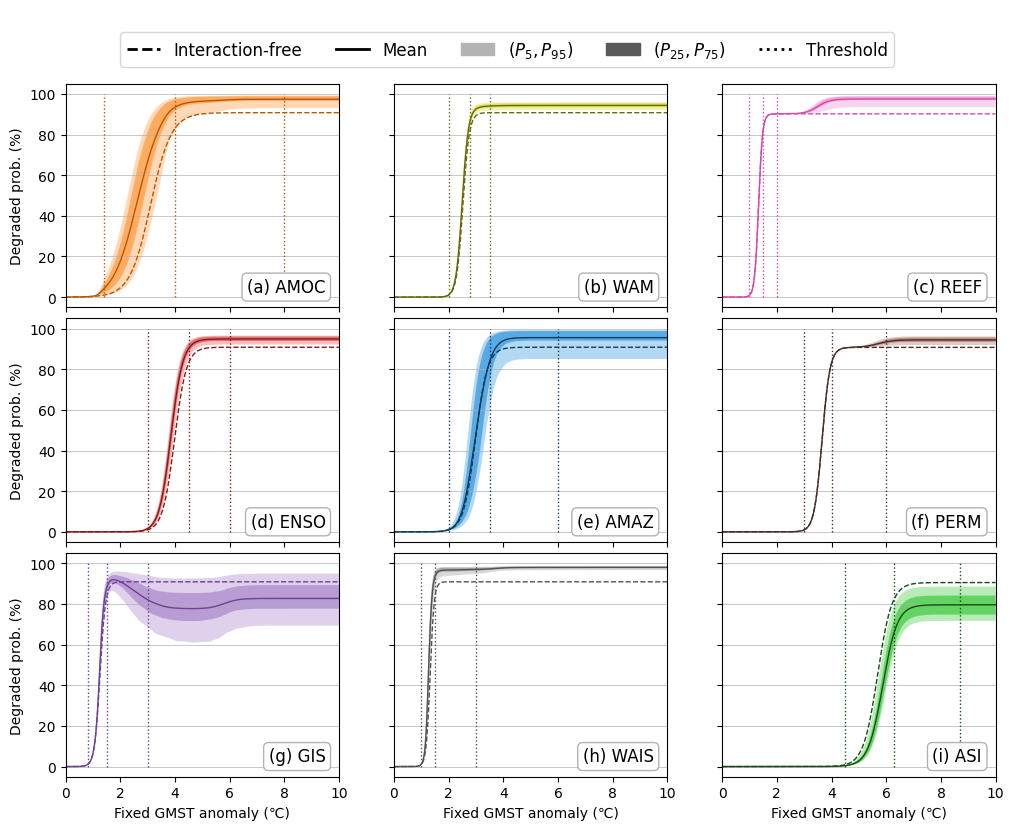

In [23]:
T = np.arange(0,10,step=0.001)
fig,axs = util.plot.TE_3x3_fig(xlabel= 'Fixed GMST anomaly (℃)',sharey=True)
TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
TE_ind = {te:i for i,te in enumerate(TEs)}
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
T_min = df_TEs['Threshold (°C) – Min.'].to_numpy()
T_max = df_TEs['Threshold (°C) – Max.'].to_numpy()
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    axs[i_ax//3,i_ax%3].plot([T_lim[i]]*2,[0,100],c=lighten_color(colors[i],1.35),ls=':',lw=1)
    axs[i_ax//3,i_ax%3].plot([T_min[i]]*2,[0,100],c=lighten_color(colors[i],1.35),ls=':',lw=1)
    axs[i_ax//3,i_ax%3].plot([T_max[i]]*2,[0,100],c=lighten_color(colors[i],1.35),ls=':',lw=1)

    util.plot.ribbon_plot(axs[i_ax//3,i_ax%3], T, D_theory[:,:,i]*100, 
                          quantiles = [0.05,0.25], color=colors[i], shade=[0.3,0.65],alpha=[1,1],label=['']*2)
    axs[i_ax//3,i_ax%3].plot(T,D_theory[:,:,i].mean(axis=0)*100,
                             c=lighten_color(colors[i],1.35), 
                             ls='-',lw=1)

    axs[i_ax//3,i_ax%3].plot(T,D_theory_noint[:,i]*100,
                             c=lighten_color(colors[i],1.35), 
                             ls='--',lw=1)

lines=[
    Line2D([0], [0], color='k', lw=2, label='Interaction-free',ls='--'),
    Line2D([0], [0], color='k', lw=2, label='Mean'),
    Patch(facecolor=lighten_color('k',0.3), 
          edgecolor=lighten_color('k',0.3), label='$(P_5,P_{95})$'),
    Patch(facecolor=lighten_color('k',0.65), 
          edgecolor=lighten_color('k',0.65), label='$(P_{25},P_{75})$'),
    Line2D([0], [0], color='k', lw=2, label='Threshold',ls=':')] 
fig.legend(handles=lines,ncols=6,loc='upper center',prop={'size':12},borderaxespad=2)
axs[0,0].set_xlim([0,10])

fig.savefig("../../Figures/Manuscript/GMSTs_r1.pdf",format='pdf',bbox_inches='tight',dpi=300)

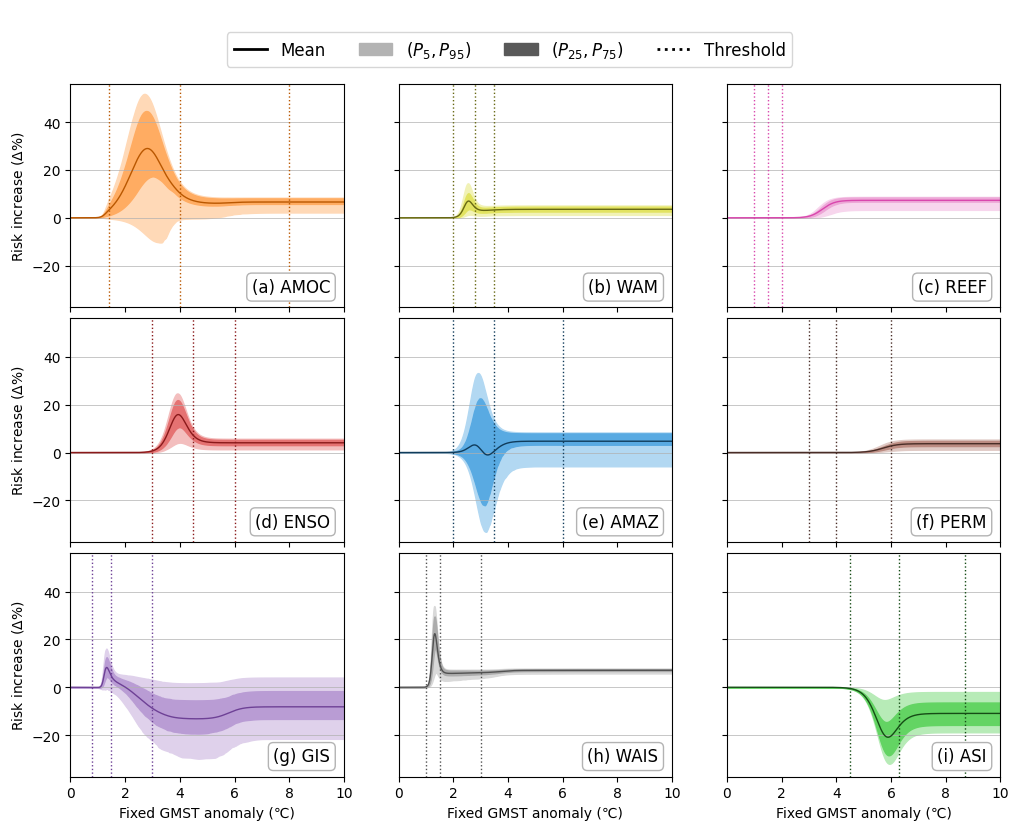

In [6]:
T = np.arange(0,10,step=0.001)
fig,axs = plt.subplots(figsize=(12,9),nrows=3,ncols=3,sharex=True,sharey=True)
# fig.subplots_adjust(hspace=0.05)
fig.subplots_adjust(hspace=0.05)

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
# linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--',(5,(10,3))]
# scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']

TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']

ann_ind = {0:1, 1:1, 2:1, 3:1, 7:1, 
           4:1, 5:1, 6:1, 8:1}
locs = [(0.05,0.95),(0.95,0.05)]
has = ['left','right']
vas = ['top','bottom']
TE_ind = {te:i for i,te in enumerate(TEs)}

T_min = df_AM22['Threshold (°C) - Min.'].to_numpy()
T_max = df_AM22['Threshold (°C) - Max.'].to_numpy()
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    # axs[i_ax//3,i_ax%3].plot([1.2,1.2],[0,100],c='k')
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='y')
    # axs[i_ax//3,i_ax%3].fill_between([T_min[i],T_max[i]],[0,0],[100,100],color=util.lighten_color('k',1),alpha=1)
    # axs[i_ax//3,i_ax%3].plot([0,10],[0]*2, c='k',lw=0.75)
    # axs[i_ax//3,i_ax%3].plot([0,10],[100]*2, c='k',lw=0.75)
    axs[i_ax//3,i_ax%3].annotate(letters[i_ax] + ' '+ TEs[i],
                                 locs[ann_ind[i_ax]],
                                 xycoords='axes fraction',
                                 ha=has[ann_ind[i_ax]],
                                 va=vas[ann_ind[i_ax]],
                                 fontsize=12,
                                 bbox=dict(fc='white',
                                           edgecolor='0.7',
                                           boxstyle='round'))

    # for r in range(500):
    #     axs[i_ax//3,i_ax%3].plot(T,D_theory[r,:,i]*100,
    #                              c=colors[i], 
    #                              ls='-',lw=0.01)
    axs[i_ax//3,i_ax%3].fill_between(T, 
                                     np.quantile(D_theory[:,:,i]*100,0.05,axis=0) -D_theory_noint[:,i]*100,
                                     np.quantile(D_theory[:,:,i]*100,0.95,axis=0) -D_theory_noint[:,i]*100,
                                     color=util.lighten_color(colors[i],0.3),
                                     edgecolor=util.lighten_color(colors[i],0.3),
                                     alpha=1)
    axs[i_ax//3,i_ax%3].fill_between(T, 
                                     np.quantile(D_theory[:,:,i]*100,0.25,axis=0)-D_theory_noint[:,i]*100,
                                     np.quantile(D_theory[:,:,i]*100,0.75,axis=0)-D_theory_noint[:,i]*100,
                                     color=util.lighten_color(colors[i],0.65),
                                     edgecolor=util.lighten_color(colors[i],0.65),
                                     alpha=1)
    axs[i_ax//3,i_ax%3].plot(T,(D_theory[:,:,i].mean(axis=0)-D_theory_noint[:,i])*100,
                             c=util.lighten_color(colors[i],1.35), 
                             ls='-',lw=1)

    # axs[i_ax//3,i_ax%3].plot(T,D_theory_noint[:,i]*100,
    #                          c=util.lighten_color(colors[i],1.35), 
    #                          ls='--',lw=1)
ylim=axs[0,0].get_ylim()
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    axs[i_ax//3,i_ax%3].plot([T_lim[i]]*2,ylim,c=util.lighten_color(colors[i],1.35),ls=':',lw=1)
    axs[i_ax//3,i_ax%3].plot([T_min[i]]*2,ylim,c=util.lighten_color(colors[i],1.35),ls=':',lw=1)
    axs[i_ax//3,i_ax%3].plot([T_max[i]]*2,ylim,c=util.lighten_color(colors[i],1.35),ls=':',lw=1)

lines=[
       Line2D([0], [0], color='k', lw=2, label='Mean'),
       Patch(facecolor=util.lighten_color('k',0.3), 
             edgecolor=util.lighten_color('k',0.3), label='$(P_5,P_{95})$'),
       Patch(facecolor=util.lighten_color('k',0.65), 
             edgecolor=util.lighten_color('k',0.65), label='$(P_{25},P_{75})$'),
    Line2D([0], [0], color='k', lw=2, label='Threshold',ls=':')] 
# lines += [Line2D([0], [0], color='k', lw=2, 
#                  label=scen_labels[j], ls = linestyles[j]) for j in range(5)]


# fig.text(0.5, 0.04, 'Fixed GMST anomaly (℃)', ha='center')
# fig.text(0.04, 0.5, 'Stationary degraded prob. (%)', va='center', rotation='vertical')
for i in range(3):
    axs[-1,i].set_xlabel('Fixed GMST anomaly (℃)')
    axs[i,0].set_ylabel(r'Risk increase ($\Delta \%$)')
    
axs[0,0].set_xlim([0,10])
axs[0,0].set_ylim(ylim)
# axs[0,0].set_ylim([0,100])

fig.legend(handles=lines,ncols=6,loc='upper center',prop={'size':12},borderaxespad=2)
fig.savefig("../Figures/TE (sigmoid)/rx10c/GMSTs_int_diff_abs.pdf",format='pdf',bbox_inches='tight',dpi=300)

In [211]:
D_theory.shape

(500, 10000, 9)

In [214]:
(D_theory[:,-1,:].mean(axis=0)-D_theory_noint[-1,:])*100

array([  4.72108565,   6.60294104, -10.94174046,   4.07209018,
        -8.17521345,   3.68695124,   7.29982925,   7.09258721,
         3.56801106])

## Temperature sensitivity

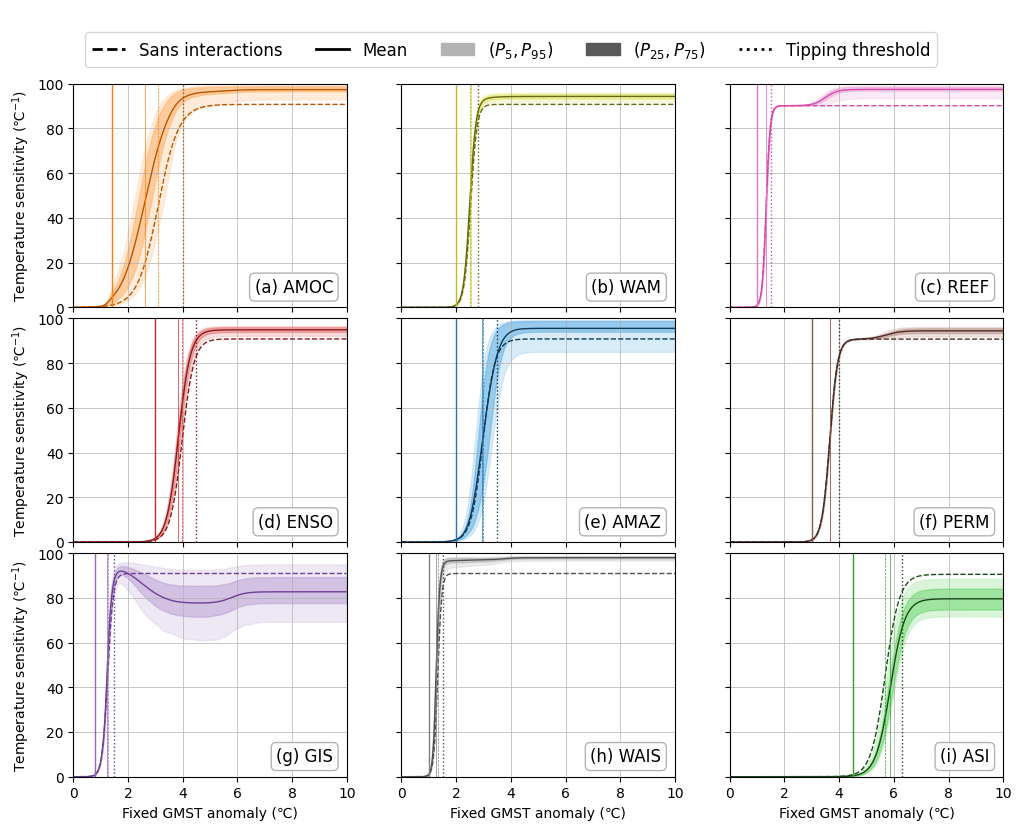

In [174]:
T = np.arange(0,10,step=0.001)
fig,axs = plt.subplots(figsize=(12,9),nrows=3,ncols=3,sharex=True,sharey=True)
# fig.subplots_adjust(hspace=0.05)
fig.subplots_adjust(hspace=0.05)

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
# linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--',(5,(10,3))]
# scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']

TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']

ann_ind = {0:1, 1:1, 2:1, 3:1, 7:1, 
           4:1, 5:1, 6:1, 8:1}
locs = [(0.05,0.95),(0.95,0.05)]
has = ['left','right']
vas = ['top','bottom']
TE_ind = {te:i for i,te in enumerate(TEs)}
data = np.gradient(D_theory,T,axis=1)
data_noint = np.gradient(D_theory_noint,T,axis=0)
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    # axs[i_ax//3,i_ax%3].plot([1.2,1.2],[0,100],c='k')
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='both')
    # axs[i_ax//3,i_ax%3].plot([0,10],[0]*2, c='k',lw=0.75)
    # axs[i_ax//3,i_ax%3].plot([0,10],[100]*2, c='k',lw=0.75)
    axs[i_ax//3,i_ax%3].annotate(letters[i_ax] + ' '+ TEs[i],
                                 locs[ann_ind[i_ax]],
                                 xycoords='axes fraction',
                                 ha=has[ann_ind[i_ax]],
                                 va=vas[ann_ind[i_ax]],
                                 fontsize=12,
                                 bbox=dict(fc='white',
                                           edgecolor='0.7',
                                           boxstyle='round'))
    # axs[i_ax//3,i_ax%3].plot([T_lim[i]]*2,[0,100],c=util.lighten_color(colors[i],1.35),ls=':',lw=1)

    # for r in range(500):
    #     axs[i_ax//3,i_ax%3].plot(T,D_theory[r,:,i]*100,
    #                              c=colors[i], 
    #                              ls='-',lw=0.01)
    axs[i_ax//3,i_ax%3].fill_between(T, 
                                     np.quantile(D_theory[:,:,i]*100,0.05,axis=0),
                                     np.quantile(D_theory[:,:,i]*100,0.95,axis=0),
                                     color=util.lighten_color(colors[i],0.3),
                                     edgecolor=util.lighten_color(colors[i],0.3),
                                     alpha=0.5)
    axs[i_ax//3,i_ax%3].fill_between(T, 
                                     np.quantile(D_theory[:,:,i]*100,0.25,axis=0),
                                     np.quantile(D_theory[:,:,i]*100,0.75,axis=0),
                                     color=util.lighten_color(colors[i],0.65),
                                     edgecolor=util.lighten_color(colors[i],0.65),
                                     alpha=0.5)
    axs[i_ax//3,i_ax%3].plot(T,D_theory[:,:,i].mean(axis=0)*100,
                             c=util.lighten_color(colors[i],1.35), 
                             ls='-',lw=1)

    axs[i_ax//3,i_ax%3].plot(T,D_theory_noint[:,i]*100,
                             c=util.lighten_color(colors[i],1.35), 
                             ls='--',lw=1)

ylim=axs[0,0].get_ylim()
T_min = df_AM22['Threshold (°C) - Min.'].to_numpy()
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    axs[i_ax//3,i_ax%3].plot([T[np.argmax(data[:,:,i].mean(axis=0))]]*2,
                             [0,100],color=colors[i],ls='-',lw=0.5)
    axs[i_ax//3,i_ax%3].plot([T_min[i]]*2,
                             [0,100],color=colors[i],ls='-',lw=1)
    axs[i_ax//3,i_ax%3].plot([T[np.argmax(data_noint[:,i])]]*2,
                             [0,100],color=colors[i],ls='--',lw=0.5)
    axs[i_ax//3,i_ax%3].plot([T_lim[i]]*2,[0,100],c=util.lighten_color(colors[i],1.35),ls=':',lw=1)
axs[0,0].set_ylim(ylim)

lines=[
       Line2D([0], [0], color='k', lw=2, label='Sans interactions',ls='--'),
       Line2D([0], [0], color='k', lw=2, label='Mean'),
       Patch(facecolor=util.lighten_color('k',0.3), 
             edgecolor=util.lighten_color('k',0.3), label='$(P_5,P_{95})$'),
       Patch(facecolor=util.lighten_color('k',0.65), 
             edgecolor=util.lighten_color('k',0.65), label='$(P_{25},P_{75})$'),
    Line2D([0], [0], color='k', lw=2, label='Tipping threshold',ls=':')] 
# lines += [Line2D([0], [0], color='k', lw=2, 
#                  label=scen_labels[j], ls = linestyles[j]) for j in range(5)]


# fig.text(0.5, 0.04, 'Fixed GMST anomaly (℃)', ha='center')
# fig.text(0.04, 0.5, 'Stationary degraded prob. (%)', va='center', rotation='vertical')
for i in range(3):
    axs[-1,i].set_xlabel('Fixed GMST anomaly (℃)')
    axs[i,0].set_ylabel(r'Temperature sensitivity (℃$^{-1}$)')
    
axs[0,0].set_xlim([0,10])
axs[0,0].set_ylim([0,100])

fig.legend(handles=lines,ncols=6,loc='upper center',prop={'size':12},borderaxespad=2)

In [172]:
df_AM22.columns

Index(['Category', 'Tipping Element', 'Threshold (°C) - Est.',
       'Threshold (°C) - Min.', 'Threshold (°C) - Max.',
       'Timescale (y) - Est.', 'Timescale (y) - Min.', 'Timescale (y) - Max.',
       'Max. Impact** (°C) - Global', 'Max. Impact** (°C) - Regional',
       'Activation Time', 'Dynamics - Self-perpetuate?',
       'Dynamics - Rate-dependent?', 'Dynamics - Hysteresis/ bistability?',
       'Comments', 'RecoveryTime', 'CollapseTime', 'T_lim', 'Sigmoid Beta',
       'RecoveryTime (Nico)'],
      dtype='object')

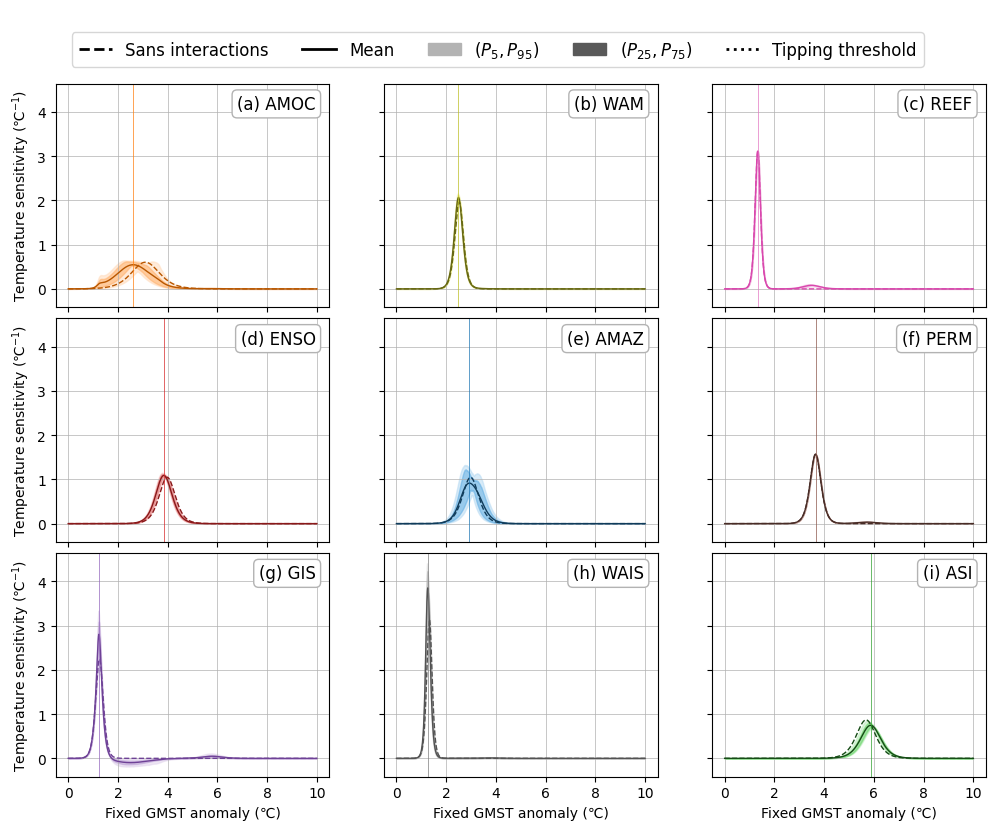

In [154]:
T = np.arange(0,10,step=0.001)
fig,axs = plt.subplots(figsize=(12,9),nrows=3,ncols=3,sharex=True,sharey=True)
# fig.subplots_adjust(hspace=0.05)
fig.subplots_adjust(hspace=0.05)

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
# linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--',(5,(10,3))]
# scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']

TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']

loc = (0.95,0.95)
ha = 'right'
va = 'top'
TE_ind = {te:i for i,te in enumerate(TEs)}
data = np.gradient(D_theory,T,axis=1)
data_noint = np.gradient(D_theory_noint,T,axis=0)
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='both')
    axs[i_ax//3,i_ax%3].annotate(letters[i_ax] + ' '+ TEs[i],
                                 loc,
                                 xycoords='axes fraction',
                                 ha=ha, va=va,
                                 fontsize=12,
                                 bbox=dict(fc='white',
                                           edgecolor='0.7',
                                           boxstyle='round'))
    axs[i_ax//3,i_ax%3].fill_between(T, 
                                     np.quantile(data[:,:,i],0.05,axis=0),
                                     np.quantile(data[:,:,i],0.95,axis=0),
                                     color=util.lighten_color(colors[i],0.3),
                                     edgecolor=util.lighten_color(colors[i],0.3),
                                     alpha=0.5)
    axs[i_ax//3,i_ax%3].fill_between(T, 
                                     np.quantile(data[:,:,i],0.25,axis=0),
                                     np.quantile(data[:,:,i],0.75,axis=0),
                                     color=util.lighten_color(colors[i],0.65),
                                     edgecolor=util.lighten_color(colors[i],0.65),
                                     alpha=0.5)
    axs[i_ax//3,i_ax%3].plot(T,data[:,:,i].mean(axis=0),
                             c=util.lighten_color(colors[i],1.35), 
                             ls='-',lw=1)

    axs[i_ax//3,i_ax%3].plot(T,data_noint[:,i],
                             c=util.lighten_color(colors[i],1.35), 
                             ls='--',lw=1)

ylim=axs[0,0].get_ylim()
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    axs[i_ax//3,i_ax%3].plot([T[np.argmax(data[:,:,i].mean(axis=0))]]*2,ylim,color=colors[i],ls='-',lw=0.5)
axs[0,0].set_ylim(ylim)

lines=[
       Line2D([0], [0], color='k', lw=2, label='Sans interactions',ls='--'),
       Line2D([0], [0], color='k', lw=2, label='Mean'),
       Patch(facecolor=util.lighten_color('k',0.3), 
             edgecolor=util.lighten_color('k',0.3), label='$(P_5,P_{95})$'),
       Patch(facecolor=util.lighten_color('k',0.65), 
             edgecolor=util.lighten_color('k',0.65), label='$(P_{25},P_{75})$'),
    Line2D([0], [0], color='k', lw=2, label='Tipping threshold',ls=':')] 
# lines += [Line2D([0], [0], color='k', lw=2, 
#                  label=scen_labels[j], ls = linestyles[j]) for j in range(5)]


# fig.text(0.5, 0.04, 'Fixed GMST anomaly (℃)', ha='center')
# fig.text(0.04, 0.5, 'Stationary degraded prob. (%)', va='center', rotation='vertical')
for i in range(3):
    axs[-1,i].set_xlabel('Fixed GMST anomaly (℃)')
    axs[i,0].set_ylabel(r'Temperature sensitivity (℃$^{-1}$)')
    
# axs[0,0].set_xlim([0,10])
# axs[0,0].set_ylim([0,100])

fig.legend(handles=lines,ncols=6,loc='upper center',prop={'size':12},borderaxespad=2)

In [141]:
df_AM22.columns

Index(['Category', 'Tipping Element', 'Threshold (°C) - Est.',
       'Threshold (°C) - Min.', 'Threshold (°C) - Max.',
       'Timescale (y) - Est.', 'Timescale (y) - Min.', 'Timescale (y) - Max.',
       'Max. Impact** (°C) - Global', 'Max. Impact** (°C) - Regional',
       'Activation Time', 'Dynamics - Self-perpetuate?',
       'Dynamics - Rate-dependent?', 'Dynamics - Hysteresis/ bistability?',
       'Comments', 'RecoveryTime', 'CollapseTime', 'T_lim', 'Sigmoid Beta',
       'RecoveryTime (Nico)'],
      dtype='object')

Text(0.5, 0, 'Critical temperature (℃)')

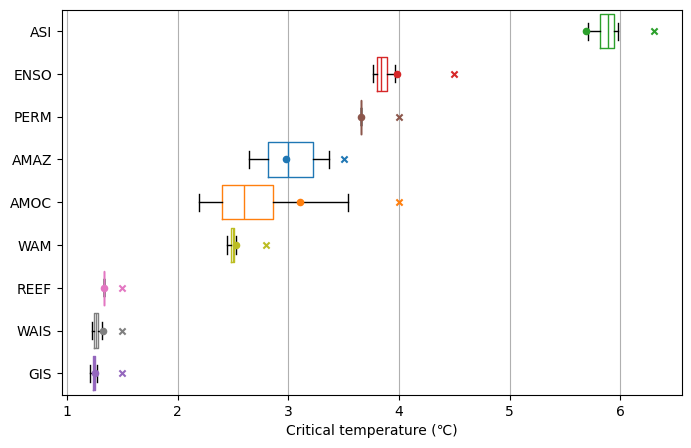

In [192]:
TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']
TE_ind = {te:i for i,te in enumerate(TEs)}

fig,ax = plt.subplots(figsize=(8,5))

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--',(5,(10,3))]
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']

grad = np.gradient(D_theory,T,axis=1)
grad_noint = np.gradient(D_theory_noint,T,axis=0)

data = T[np.argmax(grad,axis=1)] 
data_noint = T[np.argmax(grad_noint,axis=0)] 
full = sorted(zip(list(np.median(data,axis=0)),TEs,range(9)))

# T_min = df_AM22['Threshold (°C) - Min.'].to_numpy()
# T_max = df_AM22['Threshold (°C) - Max.'].to_numpy()

ax.grid(visible=True,axis='x')
for i in range(9):
    i_ax=full[i][2]
    # ax.errorbar(T_lim[i_ax],[i+1],
    #             xerr=np.array([(T_lim-T_min)[i_ax], (T_max-T_lim)[i_ax]]).reshape(2,1),
    #             color=colors[i_ax],marker='x')
    ax.scatter(T_lim[i_ax],i+1,marker='x',color=colors[i_ax],zorder=10,s=20)
    bp=ax.boxplot(data[:,i_ax],positions=[i+1], widths=0.8,vert=False,
                   patch_artist=False)
    for b in bp['boxes']:
        b.set_color(colors[i_ax])
    for b in bp['medians']:
        b.set_color(colors[i_ax])
    ax.scatter(data_noint[i_ax],[i+1],color=colors[i_ax],zorder=10,s=20)
    
    # ax.scatter([i+1],np.median(data[:,i_ax]),color=util.lighten_color(colors[i_ax],1),marker='_')
    # ax.errorbar([i+1],np.median(data[:,i_ax]),
    #             yerr=np.abs(np.quantile(data[:,i],[0.25,0.75],axis=0)
    #                         -np.median(data[:,i])).reshape(2,1),
    #             ls='',ecolor=util.lighten_color(colors[i_ax],1),
    #             marker='',barsabove=True,capsize=10)
    # ax.scatter()
# ax.set_yscale('log')
ax.set_yticks(np.arange(1,10),[full[i][1] for i in range(9)])
ax.set_xlabel('Critical temperature (℃)')
# ax.set_ylabel('Tipping element')
# ax.set_xscale('log')

In [194]:
data.shape

(500, 9)

In [202]:
data_noint-np.mean(data,axis=0)

array([-3.17140000e-02,  4.34304000e-01, -1.90166000e-01,  1.32764000e-01,
        1.55820000e-02,  2.35367281e-14,  5.77315973e-15,  5.99280000e-02,
        2.71780000e-02])

In [145]:
((T_lim-T_min)[i_ax], (T_max-T_lim)[i_ax])

(0.7, 1.5)

In [119]:
data_noint.shape

(10000,)

### Conceptual figure

In [21]:
tau_c = 50
tau_r = 10*tau_c
T_crit = 2
T_min = 1
beta = float(sigmoid_beta(T_min,T_crit,10,value_at_min=value_at_min))
Ts = np.arange(0,4,step=0.1)
q_c = 1/(tau_c+1)
p_c = util.logistic(Ts, T_crit,beta)*q_c
p_r = 1/(tau_r+1)
eq_risk = p_c/(p_c+p_r)

Text(0, 0.5, 'Equilibrium risk (%)')

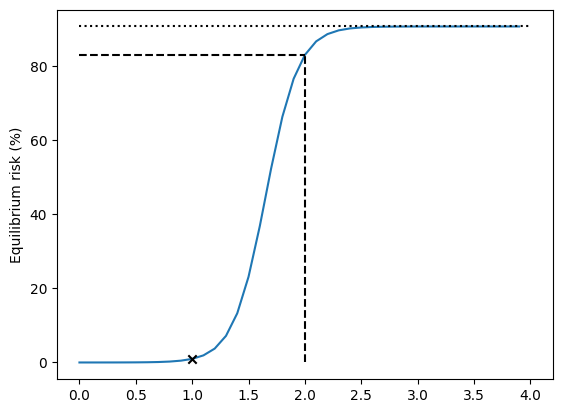

In [44]:
plt.plot(Ts,eq_risk*100)
plt.plot([0,4], [100*q_c/(q_c+p_r)]*2,ls=':',c='k')
plt.plot([0,2], [50*q_c/(q_c/2+p_r)]*2,ls='--',c='k')
plt.plot([T_crit]*2,[0,50*q_c/(q_c/2+p_r)],ls='--',c='k')

# plt.plot([0,T_min],[0.1*q_c/(0.001*q_c+p_r)]*2,ls='--',c='k')
# plt.plot([T_min]*2,[0,0.1*q_c/(0.001*q_c+p_r)],ls='--',c='k')
plt.scatter(T_min,0.1*q_c/(0.001*q_c+p_r),c='k',marker='x',zorder=2)

# plt.ylim([0,100])
plt.ylabel('Equilibrium risk (%)')

### Aggregating to the global Earth System scale

In [31]:
ES_mean = D_theory.mean(axis=0).sum(axis=-1)
ES_5 = np.quantile(D_theory.sum(axis=-1),0.05,axis=0)
ES_25= np.quantile(D_theory.sum(axis=-1),0.25,axis=0)
ES_75= np.quantile(D_theory.sum(axis=-1),0.75,axis=0)
ES_95= np.quantile(D_theory.sum(axis=-1),0.95,axis=0)
ES_noint = D_theory_noint.sum(axis=-1)

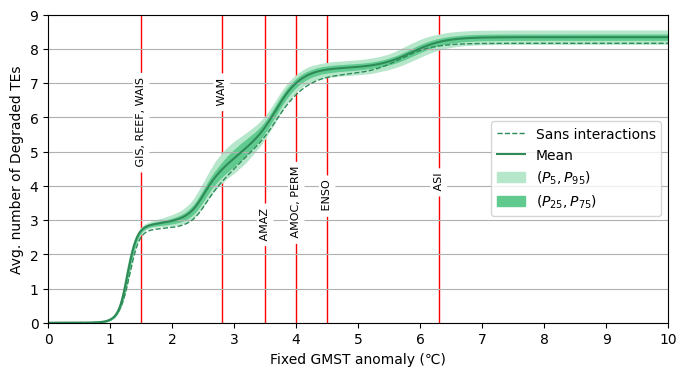

In [47]:
# fig,ax = plt.subplots(figsize=(8,5))
fig,ax = plt.subplots(figsize=(8,4))
theme_col = 'seagreen'

ax.plot(T,ES_noint,
        c=util.lighten_color(theme_col,1), 
        ls='--',lw=1,label='Sans interactions')
ax.grid(axis='y')
# ax.fill_between([1.5,2], [0,0], [9,9], color='purple',alpha=0.3)
# ax.annotate('Paris Agreement', [1.75,1.4],
#             ha='center',va='center',
#             fontsize=8,
#             bbox=dict(fc='none',edgecolor='none',boxstyle='round'),rotation=90)
ax.plot(T,ES_mean,
        color=util.lighten_color(theme_col,1),label='Mean')
ax.fill_between(T, ES_5, ES_95,
                 color=util.lighten_color(theme_col,0.3),
                 edgecolor=util.lighten_color(theme_col,0.3),
                 alpha=1,label='$(P_5,P_{95})$')
ax.fill_between(T, ES_25, ES_75,
                 color=util.lighten_color(theme_col,0.65),
                 edgecolor=util.lighten_color(theme_col,0.65),
                 alpha=1,label='$(P_{25},P_{75})$')

T_lim_unique = np.sort(df_AM22['T_lim'].unique())
TEs_by_tlim = {t: df_AM22[df_AM22['T_lim']==t].index.to_list() for t in T_lim_unique}
for t in T_lim_unique:
    if ES_mean[np.argmin(np.abs(T-t))]<4.5:
        locs = (t,(ES_mean[np.argmin(np.abs(T-t))]+9)/2)
    else:
        locs = (t,ES_mean[np.argmin(np.abs(T-t))]/2)
    ax.plot([t]*2,[0,9],ls='-',c='r',zorder=0,lw=1)
    ax.annotate(' ' + ', '.join(TEs_by_tlim[t]), locs,
                ha='center',
                va='center',
                fontsize=8,
                bbox=dict(fc='white',edgecolor='none',boxstyle='round'),rotation=90)

ax.set_xticks(np.arange(11))
ax.set_ylim([0,9])
ax.set_xlim([0,10])
ax.set_ylabel('Avg. number of Degraded TEs')
ax.set_xlabel('Fixed GMST anomaly (℃)')
legend=plt.legend(loc='center right')

fig.savefig("../Figures/TE (sigmoid)/rx10c/GMSTs_ES.pdf",format='pdf',bbox_inches='tight',dpi=300)

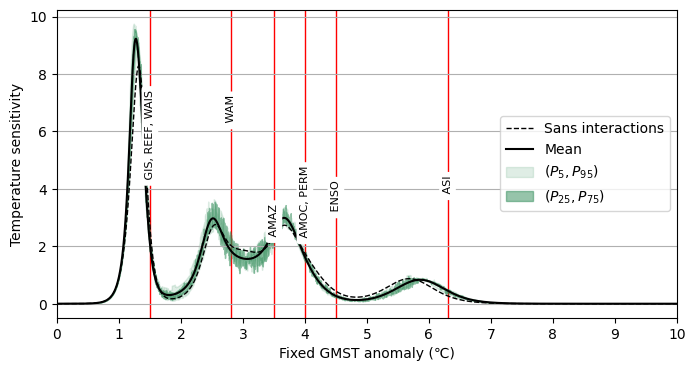

In [71]:
# fig,ax = plt.subplots(figsize=(8,5))
fig,ax = plt.subplots(figsize=(8,4))
theme_col = 'seagreen'

ax.plot(T,np.gradient(ES_noint,T),
        c='k', 
        ls='--',lw=1,label='Sans interactions')
ax.grid(axis='y')
# ax.fill_between([1.5,2], [0,0], [9,9], color='purple',alpha=0.3)
# ax.annotate('Paris Agreement', [1.75,1.4],
#             ha='center',va='center',
#             fontsize=8,
#             bbox=dict(fc='none',edgecolor='none',boxstyle='round'),rotation=90)
ax.plot(T,np.gradient(ES_mean,T),
        color='k',label='Mean')
ax.fill_between(T, 
                np.gradient(ES_5,T) , 
                np.gradient(ES_95,T),
                 color=util.lighten_color(theme_col,1),
                 edgecolor=util.lighten_color(theme_col,1),
                 alpha=0.15,label='$(P_5,P_{95})$')
ax.fill_between(T, 
                np.gradient(ES_25,T),
                np.gradient(ES_75,T),
                 color=util.lighten_color(theme_col,1),
                 edgecolor=util.lighten_color(theme_col,1),
                 alpha=0.5,label='$(P_{25},P_{75})$')
ylim = ax.get_ylim()

T_lim_unique = np.sort(df_AM22['T_lim'].unique())
TEs_by_tlim = {t: df_AM22[df_AM22['T_lim']==t].index.to_list() for t in T_lim_unique}
for t in T_lim_unique:
    if ES_mean[np.argmin(np.abs(T-t))]<4.5:
        locs = (t,(ES_mean[np.argmin(np.abs(T-t))]+9)/2)
    else:
        locs = (t,ES_mean[np.argmin(np.abs(T-t))]/2)
    ax.plot([t]*2,ylim,ls='-',c='r',zorder=0,lw=1)
    ax.annotate(' ' + ', '.join(TEs_by_tlim[t]), locs,
                ha='center',
                va='center',
                fontsize=8,
                bbox=dict(fc='white',edgecolor='none',boxstyle='round'),rotation=90)

ax.set_xticks(np.arange(11))
ax.set_ylim(ylim)
ax.set_xlim([0,10])
ax.set_ylabel('Temperature sensitivity')
ax.set_xlabel('Fixed GMST anomaly (℃)')
legend=plt.legend(loc='center right')

# fig.savefig("../Figures/TE (sigmoid)/rx10c/GMSTs_ES_gradients.pdf",format='pdf',bbox_inches='tight',dpi=300)

## Relative increase

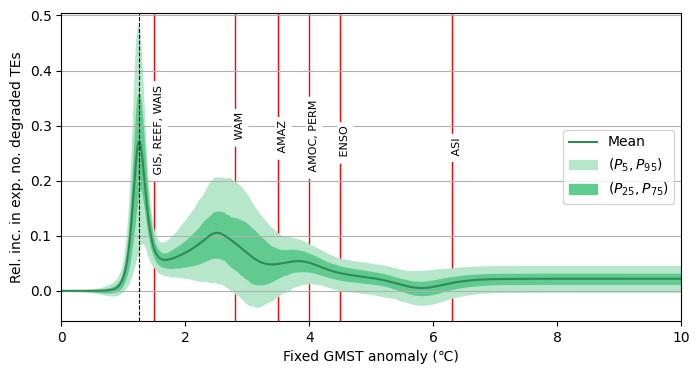

In [48]:
fig,ax = plt.subplots(figsize=(8,4))
theme_col = 'seagreen'

ax.plot(T,(ES_mean-ES_noint)/ES_noint,
        color=util.lighten_color(theme_col,1),label='Mean')
ax.fill_between(T, (ES_5-ES_noint)/ES_noint, (ES_95-ES_noint)/ES_noint,
                 color=util.lighten_color(theme_col,0.3),
                 edgecolor=util.lighten_color(theme_col,0.3),
                 alpha=1,label='$(P_5,P_{95})$')
ax.fill_between(T, (ES_25-ES_noint)/ES_noint, (ES_75-ES_noint)/ES_noint,
                 color=util.lighten_color(theme_col,0.65),
                 edgecolor=util.lighten_color(theme_col,0.65),
                 alpha=1,label='$(P_{25},P_{75})$')

ax.grid(axis='y')
ylim=ax.axes.get_ylim()

for t in T_lim_unique:
    if ((ES_mean-ES_noint)/ES_noint)[np.argmin(np.abs(T-t))]<np.mean(ylim):
        locs = (t,(((ES_mean-ES_noint)/ES_noint)[np.argmin(np.abs(T-t))]+ylim[1])/2)
    else:
        locs = (t,(((ES_mean-ES_noint)/ES_noint)[np.argmin(np.abs(T-t))]+ylim[0])/2)
    ax.plot([t]*2,ylim,ls='-',c='r',zorder=0,lw=1)
    ax.annotate(' ' + ', '.join(TEs_by_tlim[t]), locs,
                ha='left',
                va='center',
                fontsize=8,
                bbox=dict(fc='white',edgecolor='none',boxstyle='round'),rotation=90)
ax.plot([T[np.argmax((ES_mean-ES_noint)/ES_noint)]]*2,ylim,'k--',lw=0.8)

ax.set_ylim(ylim)
ax.set_xlim([0,10])
# ax.set_xticks([0,1.257,2,4,6,8,10])
ax.set_ylabel('Rel. inc. in exp. no. degraded TEs')
ax.set_xlabel('Fixed GMST anomaly (℃)')
legend=plt.legend(loc='center right')

# fig.savefig("../Figures/TE (sigmoid)/rx10c/GMSTs_ES_reltoint.pdf",format='pdf',bbox_inches='tight',dpi=300)

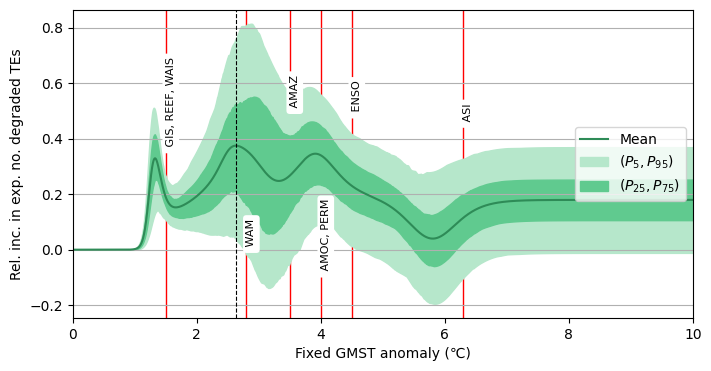

In [128]:
fig,ax = plt.subplots(figsize=(8,4))
theme_col = 'seagreen'

ax.plot(T,(ES_mean-ES_noint),
        color=util.lighten_color(theme_col,1),label='Mean')
ax.fill_between(T, (ES_5-ES_noint), (ES_95-ES_noint),
                 color=util.lighten_color(theme_col,0.3),
                 edgecolor=util.lighten_color(theme_col,0.3),
                 alpha=1,label='$(P_5,P_{95})$')
ax.fill_between(T, (ES_25-ES_noint), (ES_75-ES_noint),
                 color=util.lighten_color(theme_col,0.65),
                 edgecolor=util.lighten_color(theme_col,0.65),
                 alpha=1,label='$(P_{25},P_{75})$')

ax.grid(axis='y')
ylim=ax.axes.get_ylim()

for t in T_lim_unique:
    if ((ES_mean-ES_noint))[np.argmin(np.abs(T-t))]<np.mean(ylim):
        locs = (t,(((ES_mean-ES_noint))[np.argmin(np.abs(T-t))]+ylim[1])/2)
    else:
        locs = (t,(((ES_mean-ES_noint))[np.argmin(np.abs(T-t))]+ylim[0])/2)
    ax.plot([t]*2,ylim,ls='-',c='r',zorder=0,lw=1)
    ax.annotate(' ' + ', '.join(TEs_by_tlim[t]), locs,
                ha='left',
                va='center',
                fontsize=8,
                bbox=dict(fc='white',edgecolor='none',boxstyle='round'),rotation=90)
ax.plot([T[np.argmax(ES_mean-ES_noint)]]*2,ylim,'k--',lw=0.8)

ax.set_ylim(ylim)
ax.set_xlim([0,10])
# ax.set_xticks([0,1.257,2,4,6,8,10])
ax.set_ylabel('Rel. inc. in exp. no. degraded TEs')
ax.set_xlabel('Fixed GMST anomaly (℃)')
legend=plt.legend(loc='center right')

# fig.savefig("../Figures/TE (sigmoid)/rx10c/GMSTs_ES_reltoint.pdf",format='pdf',bbox_inches='tight',dpi=300)

In [60]:
print('Temp. at max. relative increase: ', round(T[np.argmax((ES_mean-ES_noint)/ES_noint)],3), 'C')
print('  Relative-increase: ', round(np.max((ES_mean-ES_noint)/ES_noint),4)*100, '%')
print('Temp. at max. increase: ', round(T[np.argmax((ES_mean-ES_noint))],3), 'C')
print('  Absolute-increase: ', round(np.max((ES_mean-ES_noint)),2))

Temp. at max. relative increase:  1.257 C
  Relative-increase:  27.16 %
Temp. at max. increase:  2.631 C
  Absolute-increase:  0.37


### ignore

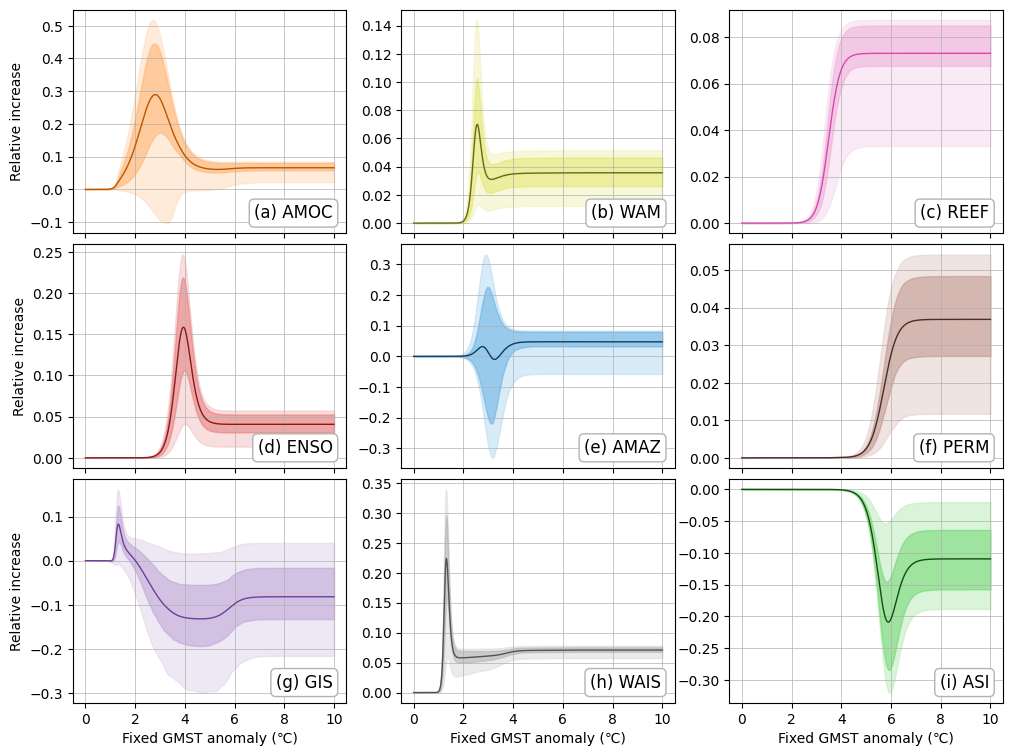

In [40]:
T = np.arange(0,10,step=0.001)
fig,axs = plt.subplots(figsize=(12,9),nrows=3,ncols=3,sharex=True,sharey=False)
fig.subplots_adjust(hspace=0.05)

rel = (D_theory - D_theory_noint)#/D_theory_noint

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--',(5,(10,3))]
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']

TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']

ann_ind = {0:1, 1:1, 2:1, 3:1, 7:1, 
           4:1, 5:1, 6:1, 8:1}
locs = [(0.05,0.95),(0.95,0.05)]
has = ['left','right']
vas = ['top','bottom']
TE_ind = {te:i for i,te in enumerate(TEs)}
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    # axs[i_ax//3,i_ax%3].plot([1.2,1.2],[0,100],c='k')
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='both')
    axs[i_ax//3,i_ax%3].annotate(letters[i_ax] + ' '+ TEs[i],
                                 locs[ann_ind[i_ax]],
                                 xycoords='axes fraction',
                                 ha=has[ann_ind[i_ax]],
                                 va=vas[ann_ind[i_ax]],
                                 fontsize=12,
                                 bbox=dict(fc='white',
                                           edgecolor='0.7',
                                           boxstyle='round'))
    # axs[i_ax//3,i_ax%3].plot([T_lim[i]]*2,[0,100],c=util.lighten_color(colors[i],1.35),ls=':',lw=1)

    # for r in range(500):
    #     axs[i_ax//3,i_ax%3].plot(T,D_theory[r,:,i]*100,
    #                              c=colors[i], 
    #                              ls='-',lw=0.01)
    axs[i_ax//3,i_ax%3].fill_between(T, 
                                     np.quantile(rel[:,:,i],0.05,axis=0),
                                     np.quantile(rel[:,:,i],0.95,axis=0),
                                     color=util.lighten_color(colors[i],0.3),
                                     edgecolor=util.lighten_color(colors[i],0.3),
                                     alpha=0.5)
    axs[i_ax//3,i_ax%3].fill_between(T, 
                                     np.quantile(rel[:,:,i],0.25,axis=0),
                                     np.quantile(rel[:,:,i],0.75,axis=0),
                                     color=util.lighten_color(colors[i],0.65),
                                     edgecolor=util.lighten_color(colors[i],0.65),
                                     alpha=0.5)
    axs[i_ax//3,i_ax%3].plot(T,np.mean(rel[:,:,i],axis=0),
                             c=util.lighten_color(colors[i],1.35), 
                             ls='-',lw=1)

lines=[
       Line2D([0], [0], color='k', lw=2, label='Sans interactions',ls='--'),
       Line2D([0], [0], color='k', lw=2, label='Mean'),
       Patch(facecolor=util.lighten_color('k',0.3), 
             edgecolor=util.lighten_color('k',0.3), label='$(P_5,P_{95})$'),
       Patch(facecolor=util.lighten_color('k',0.65), 
             edgecolor=util.lighten_color('k',0.65), label='$(P_{25},P_{75})$'),
    Line2D([0], [0], color='k', lw=2, label='Tipping threshold',ls=':')] 
lines += [Line2D([0], [0], color='k', lw=2, 
                 label=scen_labels[j], ls = linestyles[j]) for j in range(5)]


# fig.text(0.5, 0.04, 'Fixed GMST anomaly (℃)', ha='center')
# fig.text(0.04, 0.5, 'Stationary degraded prob. (%)', va='center', rotation='vertical')
for i in range(3):
    axs[-1,i].set_xlabel('Fixed GMST anomaly (℃)')
    axs[i,0].set_ylabel('Relative increase')

    # axs[0,0].set_yscale('log')
# axs[0,0].set_xlim([0,10])
# axs[0,0].set_ylim([0,100])

In [43]:
rel = (D_theory - D_theory_noint)/D_theory_noint
rel_mean = rel.mean(axis=(0,2)) # averaged over samples and over TEs
rel_5  = np.quantile(rel.mean(axis=-1),0.05,0) #((np.quantile(D_theory,0.05,axis=0)-D_theory_noint)/D_theory_noint).mean(axis=-1)
rel_25 = np.quantile(rel.mean(axis=-1),0.25,0) #((np.quantile(D_theory,0.25,axis=0)-D_theory_noint)/D_theory_noint).mean(axis=-1)
rel_75 = np.quantile(rel.mean(axis=-1),0.75,0) #((np.quantile(D_theory,0.75,axis=0)-D_theory_noint)/D_theory_noint).mean(axis=-1)
rel_95 = np.quantile(rel.mean(axis=-1),0.95,0) #((np.quantile(D_theory,0.95,axis=0)-D_theory_noint)/D_theory_noint).mean(axis=-1)

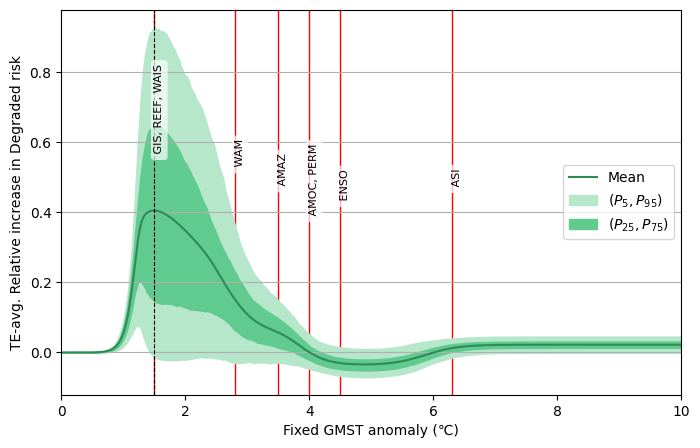

In [44]:
fig,ax = plt.subplots(figsize=(8,5))
theme_col = 'seagreen'

# rel = (D_theory - D_theory_noint)/D_theory_noint
# rel_mean = rel.mean(axis=(0,2)) # averaged over samples and over TEs
# rel_5 = np.quantile(rel,0.05,axis=0).mean(axis=-1)
# rel_25= np.quantile(rel,0.25,axis=0).mean(axis=-1)
# rel_75= np.quantile(rel,0.75,axis=0).mean(axis=-1)
# rel_95= np.quantile(rel,0.95,axis=0).mean(axis=-1)
ax.plot(T,rel_mean,
        color=util.lighten_color(theme_col,1),label='Mean')
ax.fill_between(T, rel_5, rel_95,
                 color=util.lighten_color(theme_col,0.3),
                 edgecolor=util.lighten_color(theme_col,0.3),
                 alpha=1,label='$(P_5,P_{95})$')
ax.fill_between(T, rel_25, rel_75,
                 color=util.lighten_color(theme_col,0.65),
                 edgecolor=util.lighten_color(theme_col,0.65),
                 alpha=1,label='$(P_{25},P_{75})$')

ax.grid(axis='y')
ylim=ax.axes.get_ylim()

for t in T_lim_unique:
    if rel_mean[np.argmin(np.abs(T-t))]<np.mean(ylim):
        locs = (t,(rel_mean[np.argmin(np.abs(T-t))]+ylim[1])/2)
    else:
        locs = (t,(rel_mean[np.argmin(np.abs(T-t))]+ylim[0])/2)
    ax.plot([t]*2,ylim,ls='-',c='r',zorder=0,lw=1)
    ax.annotate(' ' + ', '.join(TEs_by_tlim[t]), locs,
                ha='left',
                va='center',
                fontsize=8,
                bbox=dict(fc='white',edgecolor='none',boxstyle='round',alpha=0.7),rotation=90)
ax.plot([T[np.argmax(rel_mean)]]*2,ylim,'k--',lw=0.8)

ax.set_ylim(ylim)
ax.set_xlim([0,10])
# ax.set_xticks([0,1.257,2,4,6,8,10])
ax.set_ylabel('TE-avg. Relative increase in Degraded risk')
ax.set_xlabel('Fixed GMST anomaly (℃)')
legend=plt.legend(loc='center right')

In [24]:
T[np.argmax(rel_mean)]

1.498

In [84]:
T[np.argmax((ES_mean-ES_noint)/ES_noint)]

1.2570000000000001

In [6]:
print(((ES_25-ES_noint)/ES_noint).max(), ((ES_75-ES_noint)/ES_noint).max())

0.18723993095773733 0.35795820965044717


# Simulations under Historical/SSP warming

## Extra pre-processing

In [15]:
years = np.arange(1950, 2100) 
len_sample=500
T = len(years)
GMST_hist = df_SSPs['Historical']['Mean'].to_numpy()

p_c = np.ones((len(scenarios)-1,T,len(df_AM22)))
p_c *= 1/(df_AM22['CollapseTime'].to_numpy()+1)
for t in range(len(GMST_hist)):
    p_c[:,t,:] *= logistic(GMST_hist[t],T_lim,betas)
for t in range(len(GMST_hist),T):
    for i,s in enumerate(scenarios[1:]):
        p_c[i,t,:] *= logistic(df_SSPs[s]['Mean'].to_numpy()[t-len(GMST_hist)],T_lim,betas)

## running simulations

In [17]:
D = np.zeros((len(scenarios)-1,len_sample,len(TEs),T))
for r in tqdm.tqdm(range(len_sample)):
    for j in range(len(scenarios)-1):
        for t in range(1,T):
            D[j,r,:,t] = util.environmental_update(D[j,r,:,t-1],A[r],p_c=p_c[j,t,:],p_r=p_r)

D_noint = np.zeros((len(scenarios)-1,len(TEs),T))
for t in tqdm.tqdm(range(1,T)):
    for j in range(len(scenarios)-1):
        D_noint[j,:,t] = util.environmental_update(D_noint[j,:,t-1],np.zeros((len(TEs),len(TEs))),p_c=p_c[j,t,:],p_r=p_r)

100%|██████████████████████████████████████| 149/149 [00:00<00:00, 18483.12it/s]


In [18]:
# Saving the data
folder="../Data/Simulations/TE/Sigmoid/rx10c/SSP Warming/"
Path(folder[:-1]).mkdir(parents=True, exist_ok=True)
for i,te in enumerate(TEs):
    np.savetxt(folder+"D_"+te+"_Historical.csv", D[0,:,i,:len(GMST_hist)])
    np.savetxt(folder+"D_no_interaction_"+te+"_Historical.csv", D_noint[0,i,:len(GMST_hist)])
    for j in range(len(scenarios)-1):
        np.savetxt(folder+"D_"+te+"_"+scenarios[j+1]+".csv", D[j,:,i,len(GMST_hist):])
        np.savetxt(folder+"D_no_interaction_"+te+"_"+scenarios[j+1]+".csv", D_noint[j,i,len(GMST_hist):])

## Visualisation

In [3]:
# Loading data
years = np.arange(1950, 2100) 
SSPs = ['SSP1_1_9', 'SSP1_2_6', 'SSP2_4_5', 'SSP3_7_0', 'SSP5_8_5']
folder = "../Data/Simulations/TE/Sigmoid/rx10c/SSP Warming/"

D_hist = np.array([np.loadtxt(folder+'D_%s_Historical.csv'%te) for te in TEs])
D_ssps = np.array([[np.loadtxt(folder+'D_%s_%s.csv'%(te,ssp)) for te in TEs] for ssp in SSPs])
D_noint = np.array([[np.loadtxt(folder+'D_no_interaction_%s_%s.csv'%(te,ssp)) for te in TEs] for ssp in SSPs])

D_nointH = np.array([np.loadtxt(folder+'D_no_interaction_%s_Historical.csv'%(te)) for te in TEs])
D_nointSSP = np.array([[np.loadtxt(folder+'D_no_interaction_%s_%s.csv'%(te,ssp)) for te in TEs] for ssp in SSPs])

fpath = '../Data/IPCC AR6 Warming Data/tas_global_'
scenarios = ['Historical',
            'SSP1_1_9',
            'SSP1_2_6',
            'SSP2_4_5',
            'SSP3_7_0',
            'SSP5_8_5']
df_SSPs = {s:pd.read_csv(fpath+s+'.csv') for s in scenarios}

folder_out = '../Figures/TE (sigmoid)/rx10c/'

### Individual TEs

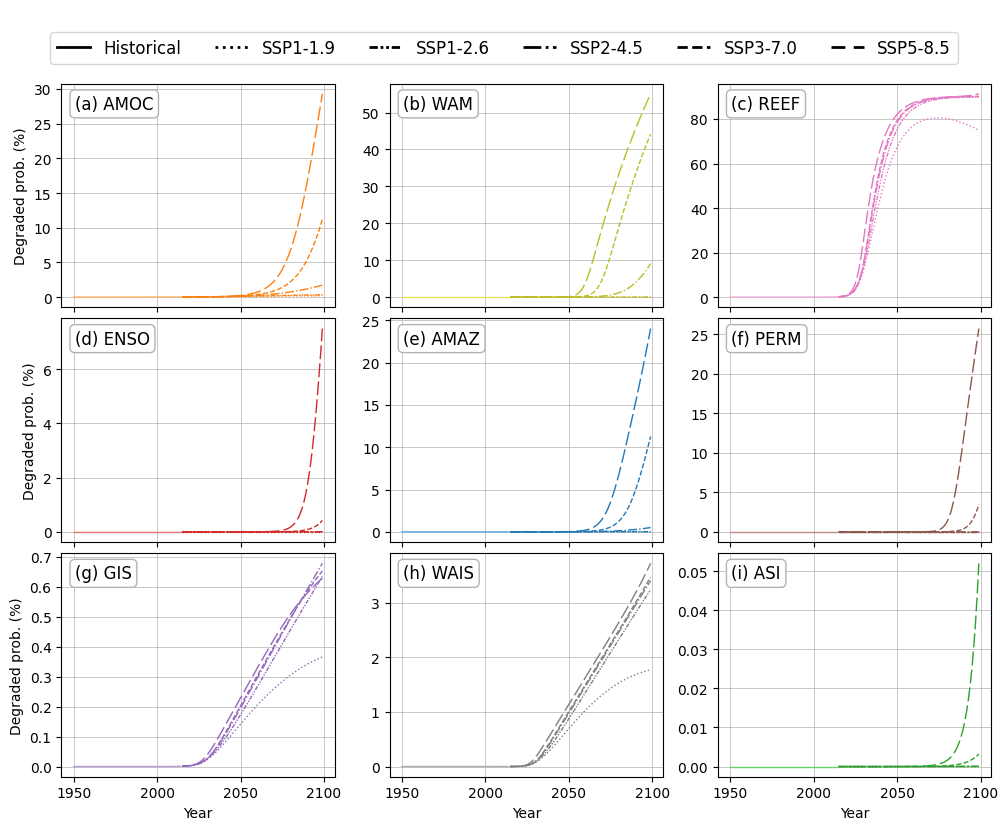

In [32]:
fig,axs = plt.subplots(figsize=(12,9),nrows=3,ncols=3,sharex=True,sharey=False)
fig.subplots_adjust(hspace=0.05) # hspace=0.05

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--',(5,(10,3))]
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']
SSP_labs = ['1-1.9', '1-2.6', '2-4.5', '3-7.0', '5-8.5']

TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']
TE_ind = {te:i for i,te in enumerate(TEs)}
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    axs[i_ax//3,i_ax%3].annotate(letters[i_ax] + ' '+ TEs[i],(0.05,0.95),
                                 xycoords='axes fraction',ha='left',va='top',fontsize=12,
                                 bbox=dict(fc='white',edgecolor='0.7',boxstyle='round'))
    axs[i_ax//3,i_ax%3].plot(years[:D_hist.shape[-1]],D_hist[i,:,:].mean(axis=0)*100,
                       c=util.lighten_color(colors[i],0.65), 
                       ls='-',lw=1)
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='both')
    for j in range(len(SSPs)):
        axs[i_ax//3,i_ax%3].plot(years[D_hist.shape[-1]:],D_ssps[j,i,:,:].mean(axis=0)*100,
                           c=colors[i], ls=linestyles[j],
                           lw=1)

lines=[Line2D([0], [0], color='k', lw=2, label='Historical')] 
lines += [Line2D([0], [0], color='k', lw=2, 
                 label=scen_labels[j], ls = linestyles[j]) for j in range(5)]

for i in range(3):
    axs[-1,i].set_xlabel('Year')
    axs[i,0].set_ylabel('Degraded prob. (%)')

fig.legend(handles=lines,ncols=6,loc='upper center',
           prop={'size':12},borderaxespad=2)
fig.savefig(folder_out+'SSPs.pdf',format='pdf',dpi=300,bbox_inches='tight')

In [112]:
D_nointSSP.shape

(5, 9, 85)

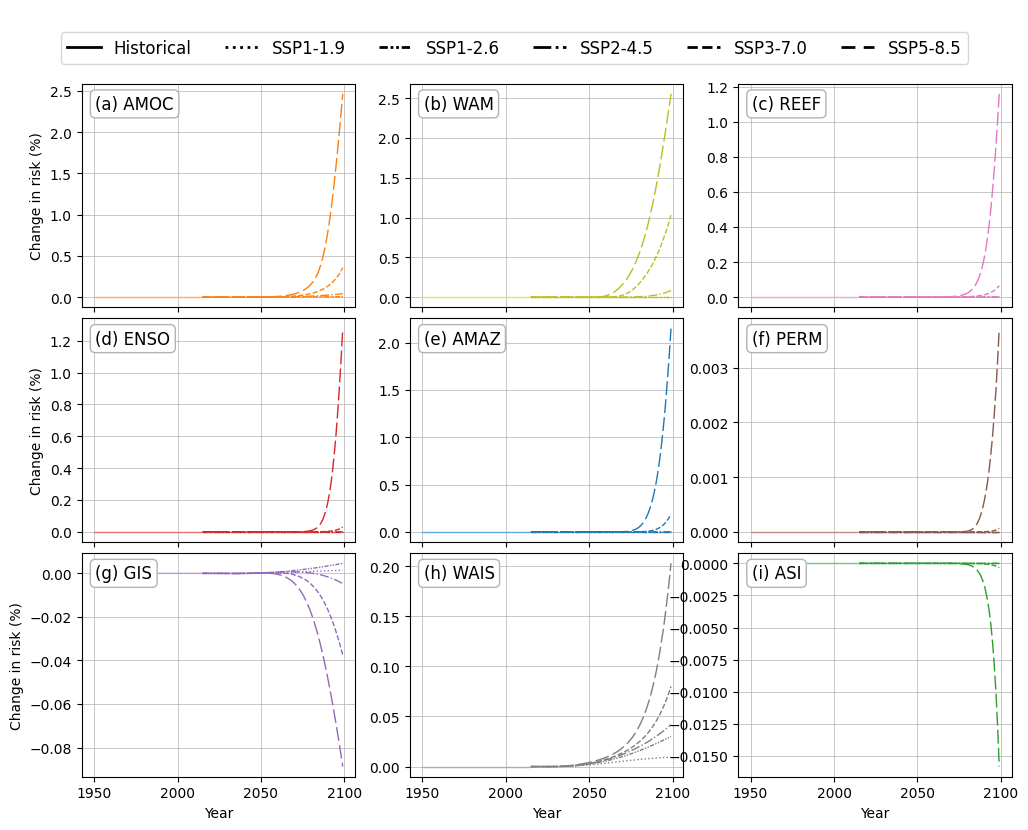

In [118]:
fig,axs = plt.subplots(figsize=(12,9),nrows=3,ncols=3,sharex=True,sharey=False)
fig.subplots_adjust(hspace=0.05) # hspace=0.05

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--',(5,(10,3))]
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']
SSP_labs = ['1-1.9', '1-2.6', '2-4.5', '3-7.0', '5-8.5']

TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']
TE_ind = {te:i for i,te in enumerate(TEs)}
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    axs[i_ax//3,i_ax%3].annotate(letters[i_ax] + ' '+ TEs[i],(0.05,0.95),
                                 xycoords='axes fraction',ha='left',va='top',fontsize=12,
                                 bbox=dict(fc='white',edgecolor='0.7',boxstyle='round'))
    axs[i_ax//3,i_ax%3].plot(years[:D_hist.shape[-1]],(D_hist[i,:,:].mean(axis=0)-D_nointH[i,:])*100,
                       c=util.lighten_color(colors[i],0.65), 
                       ls='-',lw=1)
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='both')
    for j in range(len(SSPs)):
        axs[i_ax//3,i_ax%3].plot(years[D_hist.shape[-1]:],(D_ssps[j,i,:,:].mean(axis=0)-D_noint[j,i,:])*100,
                           c=colors[i], ls=linestyles[j],
                           lw=1)

lines=[Line2D([0], [0], color='k', lw=2, label='Historical')] 
lines += [Line2D([0], [0], color='k', lw=2, 
                 label=scen_labels[j], ls = linestyles[j]) for j in range(5)]

for i in range(3):
    axs[-1,i].set_xlabel('Year')
    axs[i,0].set_ylabel('Change in risk (%)')

fig.legend(handles=lines,ncols=6,loc='upper center',
           prop={'size':12},borderaxespad=2)
fig.savefig(folder_out+'SSPs_int_diff.pdf',format='pdf',dpi=300,bbox_inches='tight')

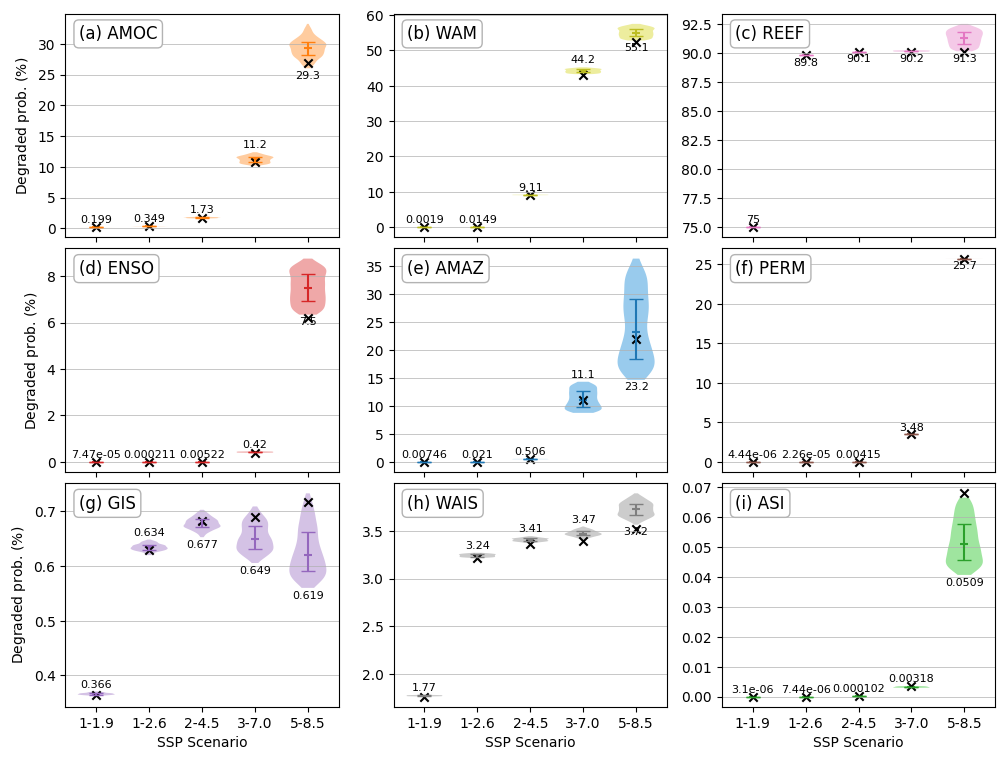

In [26]:
TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']
TE_ind = {te:i for i,te in enumerate(TEs)}

fig,axs = plt.subplots(figsize=(12,9),nrows=3,ncols=3,sharex=True,sharey=False)
fig.subplots_adjust(hspace=0.05)

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--',(5,(10,3))]
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']

parts = []
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    data = [D_ssps[j,i,:,-1]*100 for j in range(5)]

    parts.append(axs[i_ax//3,i_ax%3].violinplot(data,showmeans=False, showmedians=False,
        showextrema=False, widths=0.7))
    axs[i_ax//3,i_ax%3].annotate(letters[i_ax] + ' '+TEs[i],(0.05,0.95),xycoords='axes fraction',
                                 ha='left',va='top',fontsize=12,
                                 bbox=dict(fc='white',edgecolor='0.7',boxstyle='round'))

    x= np.arange(1,6)
    y= np.median(data,axis=1)
    yerr = np.abs(np.quantile(data,[0.25,0.75],axis=1)-y)
    # axs[i//3,i%3].scatter(x,np.mean(data,axis=1),marker='_',c='k')
    axs[i_ax//3,i_ax%3].scatter(x,y,color=util.lighten_color(colors[i],1),
                          marker='_')
    axs[i_ax//3,i_ax%3].errorbar(x,y,yerr=yerr,ls='',
                           c=util.lighten_color(colors[i],1),marker='',barsabove=True,capsize=5)
    ylim=axs[i_ax//3,i_ax%3].get_ylim()
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='y')

    # SANS INTERACTIONS SCATTER
    axs[i_ax//3,i_ax%3].scatter(np.arange(1,6),(100*D_noint[:,i,-1]),marker='x',color='k')
    
    for s in range(5):
        if data[s].max()<= 0.9*np.max(ylim):
            axs[i_ax//3,i_ax%3].annotate('%.3g'%(y[s]),
                                   [s+1,data[s].max()+0.01*(ylim[1]-ylim[0])],
                                   ha='center',va='bottom',fontsize=8)
        else:
            axs[i_ax//3,i_ax%3].annotate('%.3g'%(y[s]),
                                   [s+1,data[s].min()-0.01*(ylim[1]-ylim[0])],
                                   ha='center',va='top',fontsize=8)
    # axs[i//3,i%3].set_yscale('log')
# ax.set_ylabel(r'Degraded probability after 200y')
xlim = axs[0,0].get_xlim()
for j_ax in range(9):
    j = TE_ind[TE_ordered[j_ax]]
    # axs[j//3,j%3].plot([0,6],[D[:,:,j,-1].mean()*100]*2,c='k',ls='--',lw=0.5)
    for i,pc in enumerate(parts[j_ax]['bodies']):
        pc.set_facecolor(util.lighten_color(colors[j],0.4))
        # pc.set_edgecolor('black')
        pc.set_alpha(1)

for i in range(3):
    axs[-1,i].set_xlabel('SSP Scenario')
    axs[i,0].set_ylabel(r'Degraded prob. $(\%)$')

axs[0,0].set_xticks(range(1,6),[s[3:] for s in scen_labels])
axs[0,0].set_xlim(xlim)

fig.savefig(folder_out+'SSPs_2100.pdf',format='pdf',bbox_inches='tight',dpi=300)

### Earth System

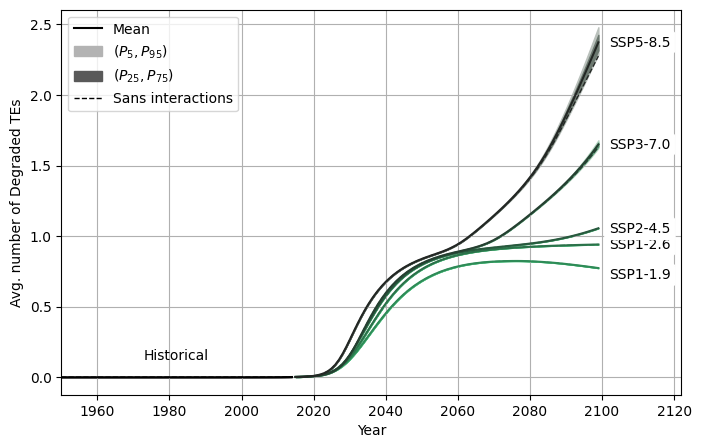

In [122]:
fig,ax = plt.subplots(figsize=(8,5))
theme_col = 'k'

ax.plot(years[:D_hist.shape[-1]],D_hist.mean(axis=1).sum(axis=0),
        color=util.lighten_color(theme_col,1),label='Mean')
ax.fill_between(years[:D_hist.shape[-1]], 
                 np.quantile(D_hist.sum(axis=0),0.05,axis=0),
                 np.quantile(D_hist.sum(axis=0),0.95,axis=0),
                 color=util.lighten_color(theme_col,0.3),
                 edgecolor=util.lighten_color(theme_col,0.3),
                 alpha=1,label='$(P_5,P_{95})$')
ax.fill_between(years[:D_hist.shape[-1]], 
                 np.quantile(D_hist.sum(axis=0),0.25,axis=0),
                 np.quantile(D_hist.sum(axis=0),0.75,axis=0),
                 color=util.lighten_color(theme_col,0.65),
                 edgecolor=util.lighten_color(theme_col,0.65),
                 alpha=1,label='$(P_{25},P_{75})$')
ax.plot(years[:D_hist.shape[-1]],D_nointH.sum(axis=0),
                             c=util.lighten_color(theme_col,1), 
                             ls='--',lw=1,label='Sans interactions')

colors = sns.dark_palette("seagreen",5)[::-1]
for j in range(5):
    ax.plot(years[D_hist.shape[-1]:],D_ssps[j,:,:,:].mean(axis=1).sum(axis=0),
        color=util.lighten_color(colors[j],1))
    ax.fill_between(years[D_hist.shape[-1]:], 
                 np.quantile(D_ssps[j,:,:,:].sum(axis=0),0.05,axis=0),
                 np.quantile(D_ssps[j,:,:,:].sum(axis=0),0.95,axis=0),
                 color=util.lighten_color(colors[j],0.3),
                 edgecolor=util.lighten_color(colors[j],0.3),
                 alpha=1)
    ax.fill_between(years[D_hist.shape[-1]:], 
                 np.quantile(D_ssps[j,:,:,:].sum(axis=0),0.25,axis=0),
                 np.quantile(D_ssps[j,:,:,:].sum(axis=0),0.75,axis=0),
                 color=util.lighten_color(colors[j],0.65),
                 edgecolor=util.lighten_color(colors[j],0.65),
                 alpha=1)
    ax.plot(years[D_hist.shape[-1]:],D_nointSSP[j,:,:].sum(axis=0),
                             c=util.lighten_color(colors[j],1), 
                             ls='--',lw=1)
    if j> 0:
        ax.annotate(scen_labels[j],(2102,D_ssps[j,:,:,:].mean(axis=1).sum(axis=0)[-1]),
                    ha='left',va='center',fontsize=10,
                    bbox=dict(fc='white',edgecolor='white',boxstyle='round'))

ax.annotate(scen_labels[0],(2102,D_ssps[0,:,:,:].mean(axis=1).sum(axis=0)[-1]),
            ha='left',va='top',fontsize=10,
            bbox=dict(fc='white',edgecolor='white',boxstyle='round'))
# ax.plot([1950,2125],[0.05*9]*2)
ax.set_xlim([1950,2122])
ax.annotate('Historical',(1982,0.1),ha='center',va='bottom',fontsize=10,
                bbox=dict(fc='none',edgecolor='none',boxstyle='round'))
# ax.set_ylim([0.5,3])

ax.grid()
ax.set_ylabel('Avg. number of Degraded TEs')
ax.set_xlabel('Year')

# cmap = mc.LinearSegmentedColormap.from_list('insert_name', [util.lighten_color(c,1) for c in colors], N=5)
# fig.colorbar(matplotlib.cm.ScalarMappable(cmap=cmap),ax=ax)

# ax.set_yscale('log')
legend=plt.legend(loc='upper left')
fig.savefig(folder_out+'ES_SSPs.pdf',format='pdf',dpi=300,bbox_inches='tight')